# TASK 2.1 – Khảo sát schema và quan hệ Airbnb Singapore

Notebook trình bày đầy đủ dữ liệu khảo sát, grain, khóa và quan hệ theo PCCV ô C9.
Hồ sơ đã chốt được đọc từ docs/source_schema_summary.csv và
docs/source_inventory.csv; sơ đồ hiện có là docs/relationship_diagram.png.
Các kết quả kiểm tra quan hệ được hiển thị trong bộ nhớ, không xuất CSV mới.
Các kiểm tra bổ sung là bằng chứng khảo sát, không thay thế các quyết định của 2.2/2.3.
Không sửa raw, không cleaning, không định nghĩa lại KPI hoặc schema warehouse.

## 1. Khởi tạo và nguồn dữ liệu


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
SURVEY_DIR = Path.cwd()
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_DIR = next((p for p in candidates if (p / "data" / "raw").is_dir()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Không tìm thấy data/raw; chạy notebook trong project nguồn.")
RAW_DIR = PROJECT_DIR / "data" / "raw"
FILES = {"Listings":"listings.csv.gz", "Calendar":"calendar.csv.gz", "Reviews":"reviews.csv.gz", "Neighbourhoods":"neighbourhoods.csv"}

def read_source(name):
    p = RAW_DIR / FILES[name]
    try:
        return pd.read_csv(p, compression="gzip" if p.suffix == ".gz" else None,
                           encoding="utf-8-sig", low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(p, compression="gzip" if p.suffix == ".gz" else None,
                           encoding="cp1252", low_memory=False)

data = {name: read_source(name) for name in FILES}
print("Project:", PROJECT_DIR)
display(pd.DataFrame([{"source":name, "file_name":FILES[name], "rows":len(df),
                       "columns":len(df.columns)} for name, df in data.items()]))


Project: E:\NKDL_DA\airbnb-singapore-data-warehouse


,source,file_name,rows,columns
0,Listings,listings.csv.gz,3208,90
1,Calendar,calendar.csv.gz,1170950,5
2,Reviews,reviews.csv.gz,46000,6
3,Neighbourhoods,neighbourhoods.csv,55,2


## 2. Hồ sơ nguồn và snapshot đã chốt
Snapshot và khoảng ngày thực tế là hai thông tin riêng biệt. Không coi toàn bộ reviews/calendar là dữ liệu phát sinh trong năm 2026.

In [2]:
ARTIFACT_DIR = PROJECT_DIR / "docs"
inventory_locked = pd.read_csv(ARTIFACT_DIR / "source_inventory.csv", encoding="utf-8-sig", keep_default_na=False)
display(inventory_locked)


,file_name,source_page_url,source_url,snapshot_date,download_date,file_size_bytes,row_count,column_count,encoding,key_columns,read_status,gzip_status,schema_status,sha256,error
0,listings.csv.gz,https://insideairbnb.com/get-the-data/,https://data.insideairbnb.com/singapore/sg/singapore/2026-09-23/data/listings.csv.gz,2026-09-23,2026-10-29,1274919,3208,90,utf-8-sig,id;neighbourhood,PASS,PASS,PASS,96dcc23048a03631aec9bbeee2f1e39b3bef871fc614e7a573df2e7dd42cb037,
1,calendar.csv.gz,https://insideairbnb.com/get-the-data/,https://data.insideairbnb.com/singapore/sg/singapore/2026-09-23/data/calendar.csv.gz,2026-09-23,2026-10-29,2685997,1170950,5,utf-8-sig,listing_id,PASS,PASS,PASS,62635a1ffd91bf87b43c7ec32f4a3059f9341e6eb82bd3ff71cc9592a0b0ece3,
2,reviews.csv.gz,https://insideairbnb.com/get-the-data/,https://data.insideairbnb.com/singapore/sg/singapore/2026-09-23/data/reviews.csv.gz,2026-09-23,2026-10-29,5239810,46000,6,utf-8-sig,listing_id;id,PASS,PASS,PASS,a84abeddb76491520626678f979c64c8f8925c881413d0a4043dac457a689ea3,
3,neighbourhoods.csv,https://insideairbnb.com/get-the-data/,https://data.insideairbnb.com/singapore/sg/singapore/2026-09-23/visualisations/neighbourhoods.csv,2026-09-23,2026-10-29,1405,55,2,utf-8-sig,neighbourhood_group;neighbourhood,PASS,N/A,PASS,b230353c2a7a71b53f6f79fa61b3010754b3b2260a70eff66e3e20df735ce38b,


## 3. Toàn bộ cột, dtype, NULL, tính phân biệt và mẫu dữ liệu đã chốt
`dtype_initial` là dtype khi khảo sát, không phải kiểu đích MySQL. Mẫu giới hạn ba giá trị; không in toàn bộ raw.

In [3]:
schema_locked = pd.read_csv(ARTIFACT_DIR / "source_schema_summary.csv", encoding="utf-8-sig", keep_default_na=False)
schema_display = schema_locked.copy()
review_personal = schema_display["source"].eq("Reviews") & schema_display["column"].isin(["comments", "reviewer_name", "reviewer_id"])
schema_display.loc[review_personal, "sample_values"] = "[Ẩn mẫu cá nhân; giữ nguyên hồ sơ CSV gốc]"
print("Số trường đã ghi nhận:", len(schema_locked))
for name in FILES:
    print("\nNguồn:", name)
    display(schema_display.loc[schema_display["source"].eq(name)])


Số trường đã ghi nhận: 103

Nguồn: Listings

Nguồn: Calendar

Nguồn: Reviews

Nguồn: Neighbourhoods


,source,file_name,column,dtype_initial,rows_in_source,columns_in_source,null_count,null_pct,unique_non_null,sample_values,date_min,date_max
0,Listings,listings.csv.gz,id,int64,3208,90,0,0.0000,3208,71609 | 71896 | 71903,,
1,Listings,listings.csv.gz,listing_url,str,3208,90,0,0.0000,3208,https://www.airbnb.com/rooms/71609 | https://www.airbnb.com/rooms/71896 | https://www.airbnb.com/rooms/71903,,
2,Listings,listings.csv.gz,scrape_id,int64,3208,90,0,0.0000,1,20260923225116,,
3,Listings,listings.csv.gz,last_scraped,str,3208,90,0,0.0000,2,2026-09-26 | 2026-09-25,2026-09-25,2026-09-26
4,Listings,listings.csv.gz,source,str,3208,90,1470,45.8229,1,previous scrape,,
5,Listings,listings.csv.gz,name,str,3208,90,0,0.0000,3122,Ensuite Room (Room 1 & 2) near EXPO | B&B Room 1 near Airport & EXPO | Room 2-near Airport & EXPO,,
6,Listings,listings.csv.gz,description,str,3208,90,21,0.6546,1972,"For 3 rooms.Book room 1&2 and room 4 | <b>The space</b><br />Vocational Stay Deluxe Bedroom in Singapore.(Near Airport) <br /> <br />Located Between <br /> - Simei and Expo Mrt <br /> - 2 bustop distance or 10-15min walking distant to Simei MRT. <br /> - Bus no 2,5,9,12,24 38. <br /> <br />Services provided <br /> - Daily Cleaning of Room <br /> - Free Usage of Ironing and Washing Machine (Detergent is not provided) <br /> - Laundry (Additional Charges) <br /> - Dryer (Additional Charges) <br /> - Change of towels, toiletries & change of bedding for extended stay. <br /> <br />Neighbourhood Consists of <br /> -A residential area <br /> -Neighbourhood Schools <br /> -East Point Shopping Mall <br />-Changi City Point (Near Expo) <br />-Tampines Business & Shopping District (Tampines Mall, Tampines 1 & Century Square) <br /> -Tampines Block 201, Housing Estate (Singaporean Cultural Spot) <br /> -Changi Simei Community Centre <br /> ~ Gym (S$3.50 per entry) <br /> ~ Badminton Court (S$3 per hour) <br /> -Neighbourhood | Like your own home, 24hrs access.",,
7,Listings,listings.csv.gz,neighborhood_overview,float64,3208,90,3208,100.0000,0,,,
8,Listings,listings.csv.gz,picture_url,str,3208,90,0,0.0000,3037,https://a0.muscache.com/pictures/24453191/35803acb_original.jpg | https://a0.muscache.com/pictures/2440674/ac4f4442_original.jpg | https://a0.muscache.com/pictures/568743/7bc623e9_original.jpg,,
9,Listings,listings.csv.gz,host_id,int64,3208,90,0,0.0000,761,367042 | 1521514 | 1975201,,


,source,file_name,column,dtype_initial,rows_in_source,columns_in_source,null_count,null_pct,unique_non_null,sample_values,date_min,date_max
90,Calendar,calendar.csv.gz,listing_id,int64,1170950,5,0,0.0,3208,71609 | 71896 | 71903,,
91,Calendar,calendar.csv.gz,date,str,1170950,5,0,0.0,366,2026-09-26 | 2026-09-27 | 2026-09-28,2026-09-25,2027-09-25
92,Calendar,calendar.csv.gz,available,str,1170950,5,0,0.0,2,t | f,,
93,Calendar,calendar.csv.gz,minimum_nights,int64,1170950,5,0,0.0,51,92 | 93 | 730,,
94,Calendar,calendar.csv.gz,maximum_nights,int64,1170950,5,0,0.0,496,1125 | 180 | 365,,


,source,file_name,column,dtype_initial,rows_in_source,columns_in_source,null_count,null_pct,unique_non_null,sample_values,date_min,date_max
95,Reviews,reviews.csv.gz,listing_id,int64,46000,6,0,0.000,1839,71609 | 71896 | 7250803,,
96,Reviews,reviews.csv.gz,id,int64,46000,6,0,0.000,41191,793880 | 1731810 | 2162194,,
97,Reviews,reviews.csv.gz,date,str,46000,6,0,0.000,4517,2011-12-19 | 2012-07-17 | 2012-09-01,2011-05-04,2026-09-25
98,Reviews,reviews.csv.gz,reviewer_id,int64,46000,6,0,0.000,38863,[Ẩn mẫu cá nhân; giữ nguyên hồ sơ CSV gốc],,
99,Reviews,reviews.csv.gz,reviewer_name,str,46000,6,0,0.000,17583,[Ẩn mẫu cá nhân; giữ nguyên hồ sơ CSV gốc],,
100,Reviews,reviews.csv.gz,comments,str,46000,6,17,0.037,39417,[Ẩn mẫu cá nhân; giữ nguyên hồ sơ CSV gốc],,


,source,file_name,column,dtype_initial,rows_in_source,columns_in_source,null_count,null_pct,unique_non_null,sample_values,date_min,date_max
101,Neighbourhoods,neighbourhoods.csv,neighbourhood_group,str,55,2,0,0.0,5,Central Region | East Region | North-East Region,,
102,Neighbourhoods,neighbourhoods.csv,neighbourhood,str,55,2,0,0.0,55,Bishan | Bukit Merah | Bukit Timah,,


## 4. Khảo sát trực tiếp dữ liệu nguồn
Giữ nguyên các phép tính của notebook gốc; bảng sau được tính lại trong bộ nhớ để đối chiếu, không xuất đè CSV đã chốt.

In [4]:
date_cols = {'Listings':['last_scraped','calendar_last_scraped','first_review','last_review'], 'Calendar':['date'], 'Reviews':['date'], 'Neighbourhoods':[]}
schema_rows = []
for name, df in data.items():
    print(f'\n### {name}: {df.shape[0]:,} hàng x {df.shape[1]} cột')
    for col in df.columns:
        vals = df[col].dropna().astype(str).drop_duplicates().head(3).tolist()
        dmin = dmax = ''
        if col in date_cols[name]:
            d = pd.to_datetime(df[col], errors='coerce')
            if d.notna().any(): dmin, dmax = d.min().date().isoformat(), d.max().date().isoformat()
        schema_rows.append({'source':name,'column':col,'dtype_initial':str(df[col].dtype),'rows':len(df),'columns':len(df.columns),'null_count':int(df[col].isna().sum()),'unique_non_null':int(df[col].nunique()),'sample_values':('[Ẩn mẫu cá nhân]' if name == 'Reviews' and col in {'comments', 'reviewer_name', 'reviewer_id'} else ' | '.join(vals)),'date_min':dmin,'date_max':dmax})
    display(df.drop(columns=["comments", "reviewer_name", "reviewer_id"], errors="ignore").head(3) if name == "Reviews" else df.head(3))
schema_summary = pd.DataFrame(schema_rows)
display(schema_summary)


### Listings: 3,208 hàng x 90 cột

### Calendar: 1,170,950 hàng x 5 cột

### Reviews: 46,000 hàng x 6 cột

### Neighbourhoods: 55 hàng x 2 cột


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,71609,https://www.airbnb.com/rooms/71609,20260923225116,2026-09-26,previous scrape,Ensuite Room (Room 1 & 2) near EXPO,For 3 rooms.Book room 1&2 and room 4,NaN,https://a0.muscache.com/pictures/24453191/35803acb_original.jpg,367042,https://www.airbnb.com/users/show/367042,1462516725725391209,https://www.airbnb.com/users/profile/1462516725725391209,Belinda,NaN,15,7,15,7,Singapore,"Hi My name is Belinda -Housekeeper \n\nI would like to welcome you to my ""Homestay Website"" \n\n\nAccomodation for: \n\n- an extended stay for studies, min 3 months\n- business,\n- training in singapore\n \n\nRoom rental are available for min 3month or longer .Room rental depending on the choice of a common sharing room (family suite) ,a standard room,a deluxe room or a triplet room which varies in sizes. We hope to give you a warm home feeling here with sweet dreams. Please forgive us if we cannot meet your high expectations.We will try our best to make your stay as comfortable as a homestay.\n\nRegards\nBelinda",NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/367042/profile_pic/1382521511/original.jpg?aki_policy=profile_x_medium,NaN,6,NaN,NaN,t,t,NaN,Tampines,East Region,1.34537,103.95887,Private room in villa,Private room,2,NaN,1 private bath,2.0,3.0,"[""Refrigerator"", ""Kitchen"", ""Luggage dropoff allowed"", ""Smoke alarm"", ""Washer"", ""Fire extinguisher"", ""Free parking on premises"", ""Wifi"", ""Dryer"", ""Private backyard \u2013 Fully fenced"", ""TV"", ""Fire pit"", ""Keypad"", ""Children\u2019s books and toys"", ""Air conditioning"", ""Hair dryer"", ""Shampoo"", ""Outdoor dining area"", ""Essentials"", ""Outdoor kitchen"", ""Long term stays allowed"", ""Hangers"", ""Hot water"", ""BBQ grill"", ""Iron"", ""Free street parking"", ""Private entrance"", ""Self check-in"", ""Outdoor furniture"", ""Cooking basics"", ""Dedicated workspace"", ""Shared hot tub""]",NaN,NaN,NaN,NaN,NaN,NaN,92.0,1125.0,92.0,92.0,1125.0,1125.0,92.0,1125.0,NaN,t,30,60,90,90,2026-09-26,19,0,0,90,0,0,NaN,2011-12-19,2020-01-17,4.44,4.37,4.00,4.63,4.78,4.26,4.32,NaN,NaN,5,0,5,0,0.11
1,71896,https://www.airbnb.com/rooms/71896,20260923225116,2026-09-26,previous scrape,B&B Room 1 near Airport & EXPO,"<b>The space</b><br />Vocational Stay Deluxe Bedroom in Singapore.(Near Airport) <br /> <br />Located Between <br /> - Simei and Expo Mrt

,listing_id,date,available,minimum_nights,maximum_nights
0,71609,2026-09-26,t,92,1125
1,71609,2026-09-27,t,92,1125
2,71609,2026-09-28,t,92,1125


,listing_id,id,date
0,71609,793880,2011-12-19
1,71609,1731810,2012-07-17
2,71609,2162194,2012-09-01


,neighbourhood_group,neighbourhood
0,Central Region,Bishan
1,Central Region,Bukit Merah
2,Central Region,Bukit Timah


,source,column,dtype_initial,rows,columns,null_count,unique_non_null,sample_values,date_min,date_max
0,Listings,id,int64,3208,90,0,3208,71609 | 71896 | 71903,,
1,Listings,listing_url,object,3208,90,0,3208,https://www.airbnb.com/rooms/71609 | https://www.airbnb.com/rooms/71896 | https://www.airbnb.com/rooms/71903,,
2,Listings,scrape_id,int64,3208,90,0,1,20260923225116,,
3,Listings,last_scraped,object,3208,90,0,2,2026-09-26 | 2026-09-25,2026-09-25,2026-09-26
4,Listings,source,object,3208,90,1470,1,previous scrape,,
5,Listings,name,object,3208,90,0,3122,Ensuite Room (Room 1 & 2) near EXPO | B&B Room 1 near Airport & EXPO | Room 2-near Airport & EXPO,,
6,Listings,description,object,3208,90,21,1972,"For 3 rooms.Book room 1&2 and room 4 | <b>The space</b><br />Vocational Stay Deluxe Bedroom in Singapore.(Near Airport) <br /> <br />Located Between <br /> - Simei and Expo Mrt <br /> - 2 bustop distance or 10-15min walking distant to Simei MRT. <br /> - Bus no 2,5,9,12,24 38. <br /> <br />Services provided <br /> - Daily Cleaning of Room <br /> - Free Usage of Ironing and Washing Machine (Detergent is not provided) <br /> - Laundry (Additional Charges) <br /> - Dryer (Additional Charges) <br /> - Change of towels, toiletries & change of bedding for extended stay. <br /> <br />Neighbourhood Consists of <br /> -A residential area <br /> -Neighbourhood Schools <br /> -East Point Shopping Mall <br />-Changi City Point (Near Expo) <br />-Tampines Business & Shopping District (Tampines Mall, Tampines 1 & Century Square) <br /> -Tampines Block 201, Housing Estate (Singaporean Cultural Spot) <br /> -Changi Simei Community Centre <br /> ~ Gym (S$3.50 per entry) <br /> ~ Badminton Court (S$3 per hour) <br /> -Neighbourhood | Like your own home, 24hrs access.",,
7,Listings,neighborhood_overview,float64,3208,90,3208,0,,,
8,Listings,picture_url,object,3208,90,0,3037,https://a0.muscache.com/pictures/24453191/35803acb_original.jpg | https://a0.muscache.com/pictures/2440674/ac4f4442_original.jpg | https://a0.muscache.com/pictures/568743/7bc623e9_original.jpg,,
9,Listings,host_id,int64,3208,90,0,761,367042 | 1521514 | 1975201,,


## 5. Đối chiếu cấu trúc nguồn với hồ sơ đã chốt

In [5]:
comparison_rows = []
for name, df in data.items():
    saved_columns = schema_locked.loc[schema_locked["source"].eq(name), "column"].tolist()
    comparison_rows.append({
        "source":name,
        "column_order_matches":list(df.columns) == saved_columns,
        "missing_vs_locked":str(sorted(set(saved_columns) - set(df.columns))),
        "added_vs_locked":str(sorted(set(df.columns) - set(saved_columns))),
        "rows_current":len(df),
        "rows_locked":int(schema_locked.loc[schema_locked["source"].eq(name), "rows_in_source"].iloc[0]),
    })
display(pd.DataFrame(comparison_rows))
print("Dtype phụ thuộc phiên bản Pandas; hồ sơ dtype đã chốt không bị ghi đè.")


Dtype phụ thuộc phiên bản Pandas; hồ sơ dtype đã chốt không bị ghi đè.


,source,column_order_matches,missing_vs_locked,added_vs_locked,rows_current,rows_locked
0,Listings,True,[],[],3208,3208
1,Calendar,True,[],[],1170950,1170950
2,Reviews,True,[],[],46000,46000
3,Neighbourhoods,True,[],[],55,55


## 6. Grain và kiểm tra khóa/liên kết gốc
Giữ nguyên cách kiểm tra đã dùng tại Task 2.1; không mặc định Reviews.id là PK khi còn trùng.

In [6]:
listings, calendar, reviews, neighbourhoods = (data[k] for k in ['Listings','Calendar','Reviews','Neighbourhoods'])
print('Listings grain: listing tại snapshot; id duy nhất:', listings['id'].is_unique if 'id' in listings else 'thiếu cột')
print('Calendar grain: listing-ngày; duplicate (listing_id,date):', calendar.duplicated(['listing_id','date']).sum() if {'listing_id','date'} <= set(calendar.columns) else 'thiếu cột')
print('Reviews grain: một review; duplicate id:', reviews['id'].duplicated().sum() if 'id' in reviews else 'thiếu cột')
print('Neighbourhoods grain: một khu vực; duplicate neighbourhood:', neighbourhoods['neighbourhood'].duplicated().sum() if 'neighbourhood' in neighbourhoods else 'thiếu cột')
listing_ids = set(listings['id'].dropna().astype(str))
for name, df in [('Calendar',calendar),('Reviews',reviews)]:
    ids = set(df['listing_id'].dropna().astype(str))
    print(name, 'listing_id không khớp Listings:', len(ids-listing_ids))
if 'neighbourhood_cleansed' in listings and 'neighbourhood' in neighbourhoods:
    a=set(listings['neighbourhood_cleansed'].dropna().astype(str)); b=set(neighbourhoods['neighbourhood'].dropna().astype(str))
    print('Neighbourhood chưa map:', sorted(a-b))
    print('Neighbourhood trong danh mục không xuất hiện ở Listings:', sorted(b-a))
print('Listings.neighbourhood NULL:', listings['neighbourhood'].isna().sum() if 'neighbourhood' in listings else 'thiếu cột')

Listings grain: listing tại snapshot; id duy nhất: True
Calendar grain: listing-ngày; duplicate (listing_id,date): 0
Reviews grain: một review; duplicate id: 4809
Neighbourhoods grain: một khu vực; duplicate neighbourhood: 0
Calendar listing_id không khớp Listings: 0
Reviews listing_id không khớp Listings: 0
Neighbourhood chưa map: []
Neighbourhood trong danh mục không xuất hiện ở Listings: ['Boon Lay', 'Changi Bay', 'Lim Chu Kang', 'Mandai', 'Marina East', 'North-Eastern Islands', 'Paya Lebar', 'Pioneer', 'Seletar', 'Simpang', 'Straits View', 'Tengah', 'Western Islands']
Listings.neighbourhood NULL: 3208


## 7. Tái hiện toàn bộ kiểm tra quan hệ gốc

In [7]:
L, C, R, N = (data[k] for k in ["Listings", "Calendar", "Reviews", "Neighbourhoods"])
checks = []
def add_check(check, value, note=""):
    checks.append({"check": check, "result": value, "note": note})

if "id" in L:
    add_check("Listings.id duplicate rows", int(L["id"].duplicated().sum()), "Kỳ vọng 0 nếu id là khóa chính")
if {"listing_id", "date"}.issubset(C.columns):
    add_check("Calendar duplicate (listing_id,date)", int(C.duplicated(["listing_id", "date"]).sum()), "Grain kỳ vọng: một listing mỗi ngày")
if "id" in R:
    add_check("Reviews.id duplicate rows", int(R["id"].duplicated().sum()), "Không kết luận id là PK nếu còn trùng")
if "neighbourhood" in N:
    add_check("Neighbourhoods.neighbourhood duplicate rows", int(N["neighbourhood"].duplicated().sum()), "Danh mục khu vực nên duy nhất theo neighbourhood")
if "id" in L:
    listing_ids = set(L["id"].dropna().astype(str))
    for source, df in [("Calendar", C), ("Reviews", R)]:
        if "listing_id" in df:
            ids = set(df["listing_id"].dropna().astype(str))
            add_check(f"{source}.listing_id orphan distinct IDs", len(ids - listing_ids), "Số listing_id không tìm thấy trong Listings.id")
if {"neighbourhood_cleansed"}.issubset(L.columns) and "neighbourhood" in N.columns:
    a = set(L["neighbourhood_cleansed"].dropna().astype(str))
    b = set(N["neighbourhood"].dropna().astype(str))
    add_check("Listings.neighbourhood_cleansed not in Neighbourhoods", len(a - b), ", ".join(sorted(a - b))[:1000])
    add_check("Neighbourhoods not used by Listings", len(b - a), ", ".join(sorted(b - a))[:1000])
if "neighbourhood" in L:
    add_check("Listings.neighbourhood NULL rows", int(L["neighbourhood"].isna().sum()), "Đối chiếu với neighbourhood_cleansed; không JOIN bằng cột này nếu NULL")

relationship_current = pd.DataFrame(checks)
display(relationship_current)


,check,result,note
0,Listings.id duplicate rows,0,Kỳ vọng 0 nếu id là khóa chính
1,"Calendar duplicate (listing_id,date)",0,Grain kỳ vọng: một listing mỗi ngày
2,Reviews.id duplicate rows,4809,Không kết luận id là PK nếu còn trùng
3,Neighbourhoods.neighbourhood duplicate rows,0,Danh mục khu vực nên duy nhất theo neighbourhood
4,Calendar.listing_id orphan distinct IDs,0,Số listing_id không tìm thấy trong Listings.id
5,Reviews.listing_id orphan distinct IDs,0,Số listing_id không tìm thấy trong Listings.id
6,Listings.neighbourhood_cleansed not in Neighbourhoods,0,
7,Neighbourhoods not used by Listings,13,"Boon Lay, Changi Bay, Lim Chu Kang, Mandai, Marina East, North-Eastern Islands, Paya Lebar, Pioneer, Seletar, Simpang, Straits View, Tengah, Western Islands"
8,Listings.neighbourhood NULL rows,3208,Đối chiếu với neighbourhood_cleansed; không JOIN bằng cột này nếu NULL


## 8. Bằng chứng bổ sung cho khóa ghép và liên kết

Giữ nguyên grain gốc. Phân biệt kiểm tra id riêng lẻ và khóa ghép quan sát được;
không tự suy ra khóa nghiệp vụ chỉ từ tính duy nhất. Đối chiếu cặp khu vực bổ sung
cho phép đối chiếu neighbourhood gốc, không thay thế quan hệ đã chốt.


In [8]:
key_rows = []
for name, keys in [
    ("Listings", ["id"]),
    ("Calendar", ["listing_id", "date"]),
    ("Reviews", ["id"]),
    ("Reviews", ["listing_id", "id"]),
    ("Neighbourhoods", ["neighbourhood"]),
    ("Neighbourhoods", ["neighbourhood_group", "neighbourhood"]),
]:
    df = data[name]
    missing = [k for k in keys if k not in df.columns]
    key_rows.append({"source":name, "candidate_key":" + ".join(keys),
        "missing_columns":str(missing),
        "rows_with_null_key":None if missing else int(df[keys].isna().any(axis=1).sum()),
        "duplicate_excess":None if missing else int(df.duplicated(keys).sum())})
display(pd.DataFrame(key_rows))
listing_ids = set(listings["id"].dropna())
link_rows = []
for name, df in [("Calendar", calendar), ("Reviews", reviews)]:
    child_ids = set(df["listing_id"].dropna())
    link_rows.append({"source":name,
        "orphan_distinct_listing_ids":len(child_ids - listing_ids),
        "orphan_non_null_rows":int((df["listing_id"].notna() & ~df["listing_id"].isin(listing_ids)).sum()),
        "null_listing_id_rows":int(df["listing_id"].isna().sum()),
        "matched_listing_count":len(child_ids & listing_ids),
        "listing_count":len(listing_ids)})
display(pd.DataFrame(link_rows))
if {"neighbourhood_group_cleansed", "neighbourhood_cleansed"} <= set(listings.columns):
    lp = set(listings[["neighbourhood_group_cleansed", "neighbourhood_cleansed"]].dropna().itertuples(index=False, name=None))
    npairs = set(neighbourhoods[["neighbourhood_group", "neighbourhood"]].dropna().itertuples(index=False, name=None))
    print("Cặp khu vực Listings không tìm thấy ở Neighbourhoods:", len(lp - npairs))


Cặp khu vực Listings không tìm thấy ở Neighbourhoods: 0


,source,candidate_key,missing_columns,rows_with_null_key,duplicate_excess
0,Listings,id,[],0,0
1,Calendar,listing_id + date,[],0,0
2,Reviews,id,[],0,4809
3,Reviews,listing_id + id,[],0,0
4,Neighbourhoods,neighbourhood,[],0,0
5,Neighbourhoods,neighbourhood_group + neighbourhood,[],0,0


,source,orphan_distinct_listing_ids,orphan_non_null_rows,null_listing_id_rows,matched_listing_count,listing_count
0,Calendar,0,0,0,3208,3208
1,Reviews,0,0,0,1839,3208


## 9. Cột trùng tên, gần nghĩa, thiếu hoặc cần rà soát

Trùng tên giữa bảng không đồng nghĩa trùng ý nghĩa: `id` của Listings khác `id`
của Reviews; `date` của Calendar khác `date` của Reviews. Các cặp cần đối chiếu
là ghi chú khảo sát, không phải lệnh đổi tên/xóa cột. Cột 100% NULL được nhận diện
để bàn giao, không kết luận tự động rằng cột không dùng.


In [9]:
column_sources = {}
for name, df in data.items():
    for column in df.columns:
        column_sources.setdefault(column, []).append(name)
display(pd.DataFrame([{"column":c, "sources":" | ".join(names)}
                      for c, names in column_sources.items() if len(names) > 1]))
print("Trường 100% NULL theo hồ sơ đã chốt:")
mask = pd.to_numeric(schema_locked["null_count"]).eq(pd.to_numeric(schema_locked["rows_in_source"]))
display(schema_locked.loc[mask])
display(pd.DataFrame([
    {"fields":"Listings.neighbourhood / neighbourhood_cleansed", "note":"Không mặc định cùng ý nghĩa; giữ cột cleansed dùng đối chiếu như hồ sơ gốc."},
    {"fields":"Listings.price / price_quote_price_per_night", "note":"Gần nghĩa; giữ quy tắc đối chiếu và đơn vị đã chốt ở 2.2, không thay KPI."},
    {"fields":"Listings.room_type / property_type", "note":"Hai phân loại khác nhau; không gộp."},
    {"fields":"Listings.id / Reviews.id", "note":"Khác thực thể; không JOIN bằng hai cột id này."},
    {"fields":"Calendar.date / Reviews.date", "note":"Ngày lịch và ngày đánh giá; không coi cùng grain."},
]))


Trường 100% NULL theo hồ sơ đã chốt:


,column,sources
0,id,Listings | Reviews
1,neighbourhood,Listings | Neighbourhoods
2,minimum_nights,Listings | Calendar
3,maximum_nights,Listings | Calendar
4,listing_id,Calendar | Reviews
5,date,Calendar | Reviews


,source,file_name,column,dtype_initial,rows_in_source,columns_in_source,null_count,null_pct,unique_non_null,sample_values,date_min,date_max
7,Listings,listings.csv.gz,neighborhood_overview,float64,3208,90,3208,100.0,0,,,
14,Listings,listings.csv.gz,host_since,float64,3208,90,3208,100.0,0,,,
21,Listings,listings.csv.gz,host_response_time,float64,3208,90,3208,100.0,0,,,
22,Listings,listings.csv.gz,host_response_rate,float64,3208,90,3208,100.0,0,,,
23,Listings,listings.csv.gz,host_acceptance_rate,float64,3208,90,3208,100.0,0,,,
25,Listings,listings.csv.gz,host_thumbnail_url,float64,3208,90,3208,100.0,0,,,
27,Listings,listings.csv.gz,host_neighbourhood,float64,3208,90,3208,100.0,0,,,
29,Listings,listings.csv.gz,host_total_listings_count,float64,3208,90,3208,100.0,0,,,
30,Listings,listings.csv.gz,host_verifications,float64,3208,90,3208,100.0,0,,,
33,Listings,listings.csv.gz,neighbourhood,float64,3208,90,3208,100.0,0,,,


,fields,note
0,Listings.neighbourhood / neighbourhood_cleansed,Không mặc định cùng ý nghĩa; giữ cột cleansed dùng đối chiếu như hồ sơ gốc.
1,Listings.price / price_quote_price_per_night,"Gần nghĩa; giữ quy tắc đối chiếu và đơn vị đã chốt ở 2.2, không thay KPI."
2,Listings.room_type / property_type,Hai phân loại khác nhau; không gộp.
3,Listings.id / Reviews.id,Khác thực thể; không JOIN bằng hai cột id này.
4,Calendar.date / Reviews.date,Ngày lịch và ngày đánh giá; không coi cùng grain.


## 10. Sơ đồ mối quan hệ sơ bộ
Hiển thị PNG hiện có trong docs/ và giữ phần giải thích Mermaid gốc.
PK/FK là định hướng khảo sát, không phải ràng buộc MySQL đã triển khai.

Mermaid nguyên văn để đọc khi trình xem không render:
# Sơ đồ quan hệ sơ bộ – Airbnb Singapore (Mục 2.1)

```mermaid
erDiagram
    NEIGHBOURHOODS ||--o{ LISTINGS : "neighbourhood_cleansed = neighbourhood"
    LISTINGS ||--o{ CALENDAR : "id = listing_id"
    LISTINGS ||--o{ REVIEWS : "id = listing_id"

    NEIGHBOURHOODS {
        string neighbourhood PK
        string neighbourhood_group
    }
    LISTINGS {
        int id PK
        string neighbourhood_cleansed FK
        string room_type
        string property_type
    }
    CALENDAR {
        int listing_id FK
        date date PK_part
        boolean available
        float price
    }
    REVIEWS {
        int id "review ID - cần xác minh duy nhất"
        int listing_id FK
        date date
        string reviewer_name
    }
```

## Grain
- **Listings:** một listing tại snapshot.
- **Calendar:** một listing tại một ngày; khóa ứng viên `(listing_id, date)`.
- **Reviews:** một review; `listing_id` liên kết Listings. Không mặc địn

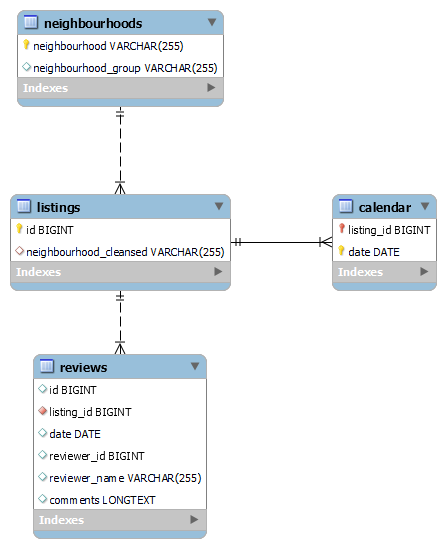

# Sơ đồ quan hệ sơ bộ – Airbnb Singapore (Mục 2.1)

```mermaid
erDiagram
    NEIGHBOURHOODS ||--o{ LISTINGS : "neighbourhood_cleansed = neighbourhood"
    LISTINGS ||--o{ CALENDAR : "id = listing_id"
    LISTINGS ||--o{ REVIEWS : "id = listing_id"

    NEIGHBOURHOODS {
        string neighbourhood PK
        string neighbourhood_group
    }
    LISTINGS {
        int id PK
        string neighbourhood_cleansed FK
        string room_type
        string property_type
    }
    CALENDAR {
        int listing_id FK
        date date PK_part
        boolean available
        float price
    }
    REVIEWS {
        int id "review ID - cần xác minh duy nhất"
        int listing_id FK
        date date
        string reviewer_name
    }
```

## Grain
- **Listings:** một listing tại snapshot.
- **Calendar:** một listing tại một ngày; khóa ứng viên `(listing_id, date)`.
- **Reviews:** một review; `listing_id` liên kết Listings. Không mặc định `id` là duy nhất nếu kiểm tra phát hiện trùng.
- **Neighbourhoods:** một khu vực; `neighbourhood` là khóa liên kết dự kiến.

## Quy tắc liên kết sơ bộ
- `Listings.id` → `Calendar.listing_id`.
- `Listings.id` → `Reviews.listing_id`.
- `Listings.neighbourhood_cleansed` → `Neighbourhoods.neighbourhood`.
- Không dùng `Listings.neighbourhood` để JOIN nếu cột này thiếu hoặc NULL.

Các kết luận cuối cùng cần căn cứ vào `relationship_checks.csv`; không tự ý loại bỏ dòng trùng hoặc NULL ở bước khảo sát.


In [10]:
from IPython.display import Image
image_path = ARTIFACT_DIR / "relationship_diagram.png"
if image_path.exists():
    display(Image(filename=str(image_path)))
else:
    print("Không có PNG tại docs/relationship_diagram.png; xem Mermaid bên dưới.")
diagram_text = '# Sơ đồ quan hệ sơ bộ – Airbnb Singapore (Mục 2.1)\n\n```mermaid\nerDiagram\n    NEIGHBOURHOODS ||--o{ LISTINGS : "neighbourhood_cleansed = neighbourhood"\n    LISTINGS ||--o{ CALENDAR : "id = listing_id"\n    LISTINGS ||--o{ REVIEWS : "id = listing_id"\n\n    NEIGHBOURHOODS {\n        string neighbourhood PK\n        string neighbourhood_group\n    }\n    LISTINGS {\n        int id PK\n        string neighbourhood_cleansed FK\n        string room_type\n        string property_type\n    }\n    CALENDAR {\n        int listing_id FK\n        date date PK_part\n        boolean available\n        float price\n    }\n    REVIEWS {\n        int id "review ID - cần xác minh duy nhất"\n        int listing_id FK\n        date date\n        string reviewer_name\n    }\n```\n\n## Grain\n- **Listings:** một listing tại snapshot.\n- **Calendar:** một listing tại một ngày; khóa ứng viên `(listing_id, date)`.\n- **Reviews:** một review; `listing_id` liên kết Listings. Không mặc định `id` là duy nhất nếu kiểm tra phát hiện trùng.\n- **Neighbourhoods:** một khu vực; `neighbourhood` là khóa liên kết dự kiến.\n\n## Quy tắc liên kết sơ bộ\n- `Listings.id` → `Calendar.listing_id`.\n- `Listings.id` → `Reviews.listing_id`.\n- `Listings.neighbourhood_cleansed` → `Neighbourhoods.neighbourhood`.\n- Không dùng `Listings.neighbourhood` để JOIN nếu cột này thiếu hoặc NULL.\n\nCác kết luận cuối cùng cần căn cứ vào `relationship_checks.csv`; không tự ý loại bỏ dòng trùng hoặc NULL ở bước khảo sát.\n'
display(Markdown(diagram_text))
print("Mermaid nguyên văn để đọc khi trình xem không render:")
print(diagram_text)


## 11. Đối chiếu PCCV và giới hạn kết luận

| PCCV Task 2.1 | Bằng chứng trong notebook |
|---|---|
| Tên cột, dtype, số hàng/cột, mẫu và phạm vi ngày | Mục 1–5, đủ toàn bộ trường |
| Phân biệt grain bốn nguồn | Mục 6–8 và sơ đồ gốc |
| Kiểm tra id/listing_id/neighbourhood và liên kết | Mục 6–8 |
| Nhận diện trường trùng nghĩa, thiếu/cần rà soát | Mục 9; không tự xóa/gộp |
| source_schema_summary.csv và sơ đồ quan hệ sơ bộ | Đọc hồ sơ và sơ đồ hiện có ở mục 3, 10; mục 7 tái hiện kiểm tra gốc |

Không sửa quy tắc cleaning của 2.4, mô hình warehouse, Data Dictionary hoặc KPI 2.2.
Calendar không thể được diễn giải trực tiếp thành booking/occupancy thực tế.
Reviews.id trùng riêng lẻ được giữ nguyên như phát hiện gốc; khóa ghép chỉ được
bổ sung bằng chứng. Notebook không sửa raw hoặc các sản phẩm đã chốt.
